# Online Shoppers Intention: Exploratory Data Analysis



# Overview
Source: https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset

Cite: C. Sakar and Y. Kastro. "Online Shoppers Purchasing Intention Dataset," UCI Machine Learning Repository, 2018. [Online]. Available: https://doi.org/10.24432/C5F88Q.

License: This dataset is licensed under a Creative Commons Attribution 4.0 International (CC BY 4.0) license.


## SETUP

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split,  StratifiedShuffleSplit
from sklearn.linear_model import  LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score,
    roc_auc_score, roc_curve
)


Load the workspace CSV, inspect its rows and data quality, prepare categorical fields, summarize measured numeric features, and plot their distributions.

In [10]:


data_path = Path("datasets") / "online_shoppers_intention.csv"
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

print("\nColumn data types:")
display(df.dtypes.rename("dtype").to_frame())

Dataset shape: 12,330 rows × 18 columns


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Column data types:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## Data quality and preparation

Keep the original data unchanged. Represent month and coded/boolean fields as categories; do not impute or drop rows unless missing values are found. Operating-system, browser, region, and traffic-type numbers are category codes, not measurements.

In [11]:
df_prepared = df.copy()

month_order = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df_prepared["Month"] = pd.Categorical(df_prepared["Month"], categories=month_order, ordered=True)
categorical_columns = [
    "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend", "Revenue"
]
df_prepared[categorical_columns] = df_prepared[categorical_columns].astype("category")

missing_summary = pd.DataFrame({
    "missing_values": df_prepared.isna().sum(),
    "missing_percent": (df_prepared.isna().mean() * 100).round(2),
})
print(f"Total missing values: {int(df_prepared.isna().sum().sum()):,}")
display(missing_summary)

print(f"Rows retained after preparation: {len(df_prepared):,} of {len(df):,}")
display(df_prepared.dtypes.rename("prepared_dtype").to_frame())

Total missing values: 0


,missing_values,missing_percent
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


Rows retained after preparation: 12,330 of 12,330


,prepared_dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## Stratified train, validation, and test split

Split the prepared data into 70% training, 15% validation, and 15% test sets. Stratifying each split by `Revenue` keeps the purchase/non-purchase proportions similar across all sets.

In [12]:
target_column = "Revenue"
X = df_prepared.drop(columns=[target_column])
y = df_prepared[target_column]

X_train_validation, X_test, y_train_validation, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Split out 15% of the full dataset for validation from the remaining 85%.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_validation,
    y_train_validation,
    test_size=0.15 / 0.85,
    random_state=RANDOM_STATE,
    stratify=y_train_validation,
)

class_proportions = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True),
    "Training set": y_train.value_counts(normalize=True),
    "Validation set": y_val.value_counts(normalize=True),
    "Test set": y_test.value_counts(normalize=True),
}).mul(100).round(2)

print(f"Training samples: {len(X_train):,} ({len(X_train) / len(X):.0%})")
print(f"Validation samples: {len(X_val):,} ({len(X_val) / len(X):.0%})")
print(f"Test samples: {len(X_test):,} ({len(X_test) / len(X):.0%})")
display(class_proportions.rename_axis("Revenue (%)"))

Training samples: 8,630 (70%)
Validation samples: 1,850 (15%)
Test samples: 1,850 (15%)


,Full dataset,Training set,Validation set,Test set
Revenue (%),,,,
False,84.53,84.52,84.54,84.54
True,15.47,15.48,15.46,15.46


## Logistic regression and random forest validation

Fit both models on the training set and compare accuracy, precision, F1, and ROC AUC on the validation set. Preprocessing is fitted inside each training pipeline. The test set is not used in model fitting, threshold selection, or evaluation.

,Accuracy,Precision,F1,ROC AUC
Model,,,,
Random Forest,0.898,0.780,0.588,0.915
Logistic Regression,0.882,0.736,0.493,0.890


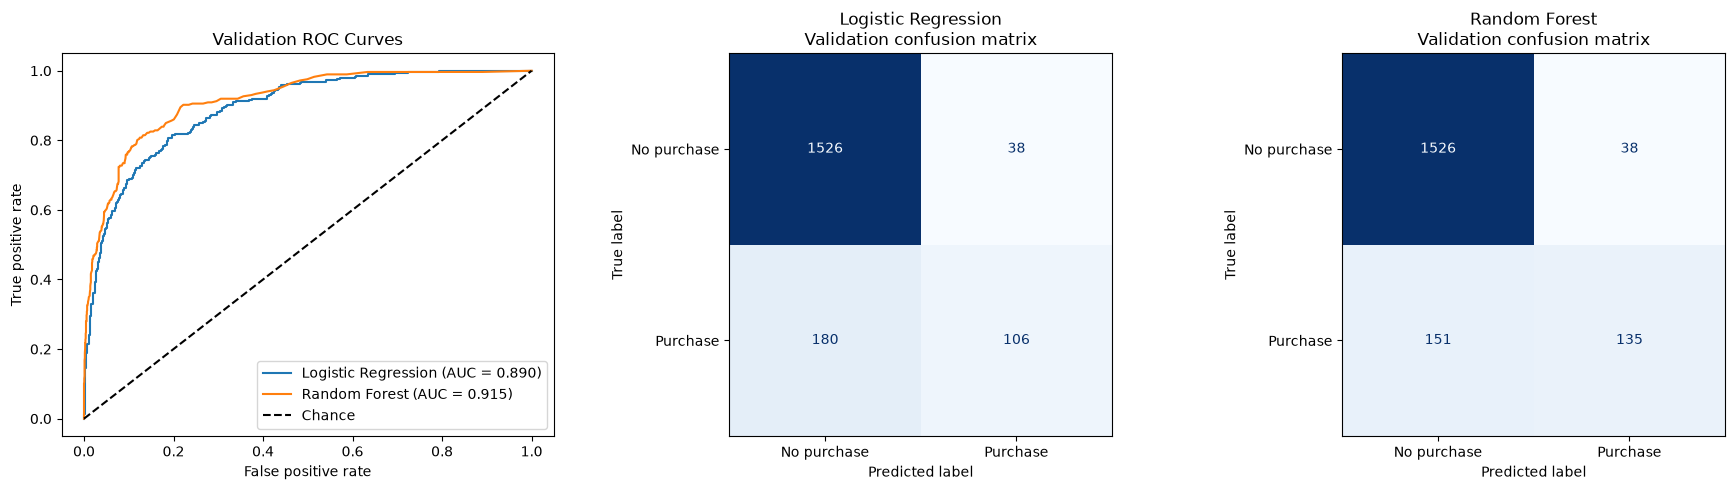

In [13]:
categorical_features = X_train.select_dtypes(include=["category", "object", "bool"]).columns.tolist()
numeric_features = [column for column in X_train.columns if column not in categorical_features]

# Convert pandas categorical columns to object so imputing and one-hot encoding handle string categories.
X_train_model = X_train.copy()
X_val_model = X_val.copy()
X_train_model[categorical_features] = X_train_model[categorical_features].astype(object)
X_val_model[categorical_features] = X_val_model[categorical_features].astype(object)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_features,
        ),
    ]
)

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

validation_predictions = {}
validation_probabilities = {}
metric_rows = []

for model_name, model in models.items():
    model.fit(X_train_model, y_train)
    predictions = model.predict(X_val_model)
    positive_class_index = list(model.named_steps["classifier"].classes_).index(True)
    probabilities = model.predict_proba(X_val_model)[:, positive_class_index]

    validation_predictions[model_name] = predictions
    validation_probabilities[model_name] = probabilities
    metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, probabilities),
    })

validation_metrics = pd.DataFrame(metric_rows).set_index("Model").sort_values("F1", ascending=False)
display(validation_metrics.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for model_name, model in models.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_val, validation_probabilities[model_name], pos_label=True
    )
    auc = validation_metrics.loc[model_name, "ROC AUC"]
    axes[0].plot(false_positive_rate, true_positive_rate, label=f"{model_name} (AUC = {auc:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("Validation ROC Curves")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(loc="lower right")

for ax, (model_name, predictions) in zip(axes[1:], validation_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        labels=[False, True],
        display_labels=["No purchase", "Purchase"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{model_name}\nValidation confusion matrix")

fig.tight_layout()
plt.show()

## Mean, median, and standard deviation

Statistics below cover page counts, durations, rates, and page values. Categorical ID codes are excluded because their arithmetic mean or standard deviation is not substantively meaningful.

In [14]:
measurement_columns = [
    "Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
statistics = pd.DataFrame({
    "mean": df_prepared[measurement_columns].mean(),
    "median": df_prepared[measurement_columns].median(),
    "std_deviation": df_prepared[measurement_columns].std(),
}).round(3)
display(statistics)

,mean,median,std_deviation
Administrative,2.315,1.000,3.322
Administrative_Duration,80.819,7.500,176.779
Informational,0.504,0.000,1.270
Informational_Duration,34.472,0.000,140.749
ProductRelated,31.731,18.000,44.476
ProductRelated_Duration,1194.746,598.937,1913.669
BounceRates,0.022,0.003,0.048
ExitRates,0.043,0.025,0.049
PageValues,5.889,0.000,18.568
SpecialDay,0.061,0.000,0.199


## Feature and revenue correlations

The Pearson correlation matrix and heatmap below use numeric session measurements and `Revenue`. `Revenue` is converted to 0/1, so its Pearson correlations are equivalent to point-biserial correlations. Categorical features, including category-coded identifiers, are omitted because their numeric codes do not represent meaningful quantities. Correlations describe associations, not causation.

Pearson correlation matrix:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Revenue
Administrative,1.00,0.60,0.38,0.26,0.43,0.37,-0.22,-0.32,0.10,-0.09,0.14
Administrative_Duration,0.60,1.00,0.30,0.24,0.29,0.36,-0.14,-0.21,0.07,-0.07,0.09
Informational,0.38,0.30,1.00,0.62,0.37,0.39,-0.12,-0.16,0.05,-0.05,0.10
Informational_Duration,0.26,0.24,0.62,1.00,0.28,0.35,-0.07,-0.11,0.03,-0.03,0.07
ProductRelated,0.43,0.29,0.37,0.28,1.00,0.86,-0.20,-0.29,0.06,-0.02,0.16
ProductRelated_Duration,0.37,0.36,0.39,0.35,0.86,1.00,-0.18,-0.25,0.05,-0.04,0.15
BounceRates,-0.22,-0.14,-0.12,-0.07,-0.20,-0.18,1.00,0.91,-0.12,0.07,-0.15
ExitRates,-0.32,-0.21,-0.16,-0.11,-0.29,-0.25,0.91,1.00,-0.17,0.10,-0.21
PageValues,0.10,0.07,0.05,0.03,0.06,0.05,-0.12,-0.17,1.00,-0.06,0.49
SpecialDay,-0.09,-0.07,-0.05,-0.03,-0.02,-0.04,0.07,0.10,-0.06,1.00,-0.08


Correlations with Revenue, sorted by absolute strength:


,Correlation with Revenue
PageValues,0.493
ExitRates,-0.207
ProductRelated,0.159
ProductRelated_Duration,0.152
BounceRates,-0.151
Administrative,0.139
Informational,0.095
Administrative_Duration,0.094
SpecialDay,-0.082
Informational_Duration,0.070


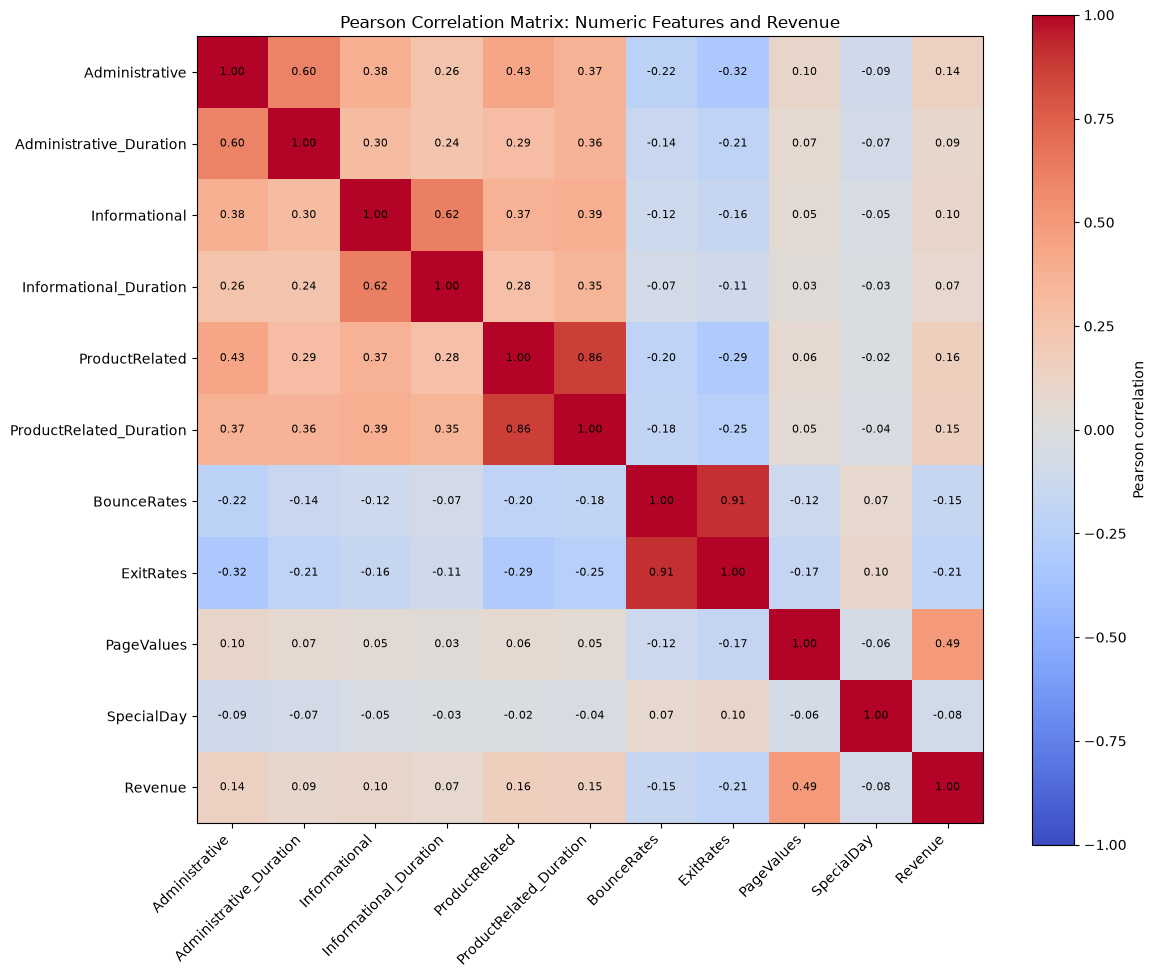

In [15]:
correlation_data = df_prepared[measurement_columns].assign(
    Revenue=df_prepared["Revenue"].astype("int8")
)
correlation_matrix = correlation_data.corr(method="pearson")

print("Pearson correlation matrix:")
display(correlation_matrix.round(2))

print("Correlations with Revenue, sorted by absolute strength:")
revenue_correlations = (
    correlation_matrix["Revenue"]
    .drop("Revenue")
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .to_frame("Correlation with Revenue")
)
display(revenue_correlations.round(3))

fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(correlation_matrix.columns)))
ax.set_yticks(np.arange(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation_matrix.index)
ax.set_title("Pearson Correlation Matrix: Numeric Features and Revenue")

for row in range(len(correlation_matrix.index)):
    for column in range(len(correlation_matrix.columns)):
        ax.text(column, row, f"{correlation_matrix.iloc[row, column]:.2f}",
                ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

## Feature distributions

Histograms show measured numeric features. Bar charts show categorical and boolean feature counts.

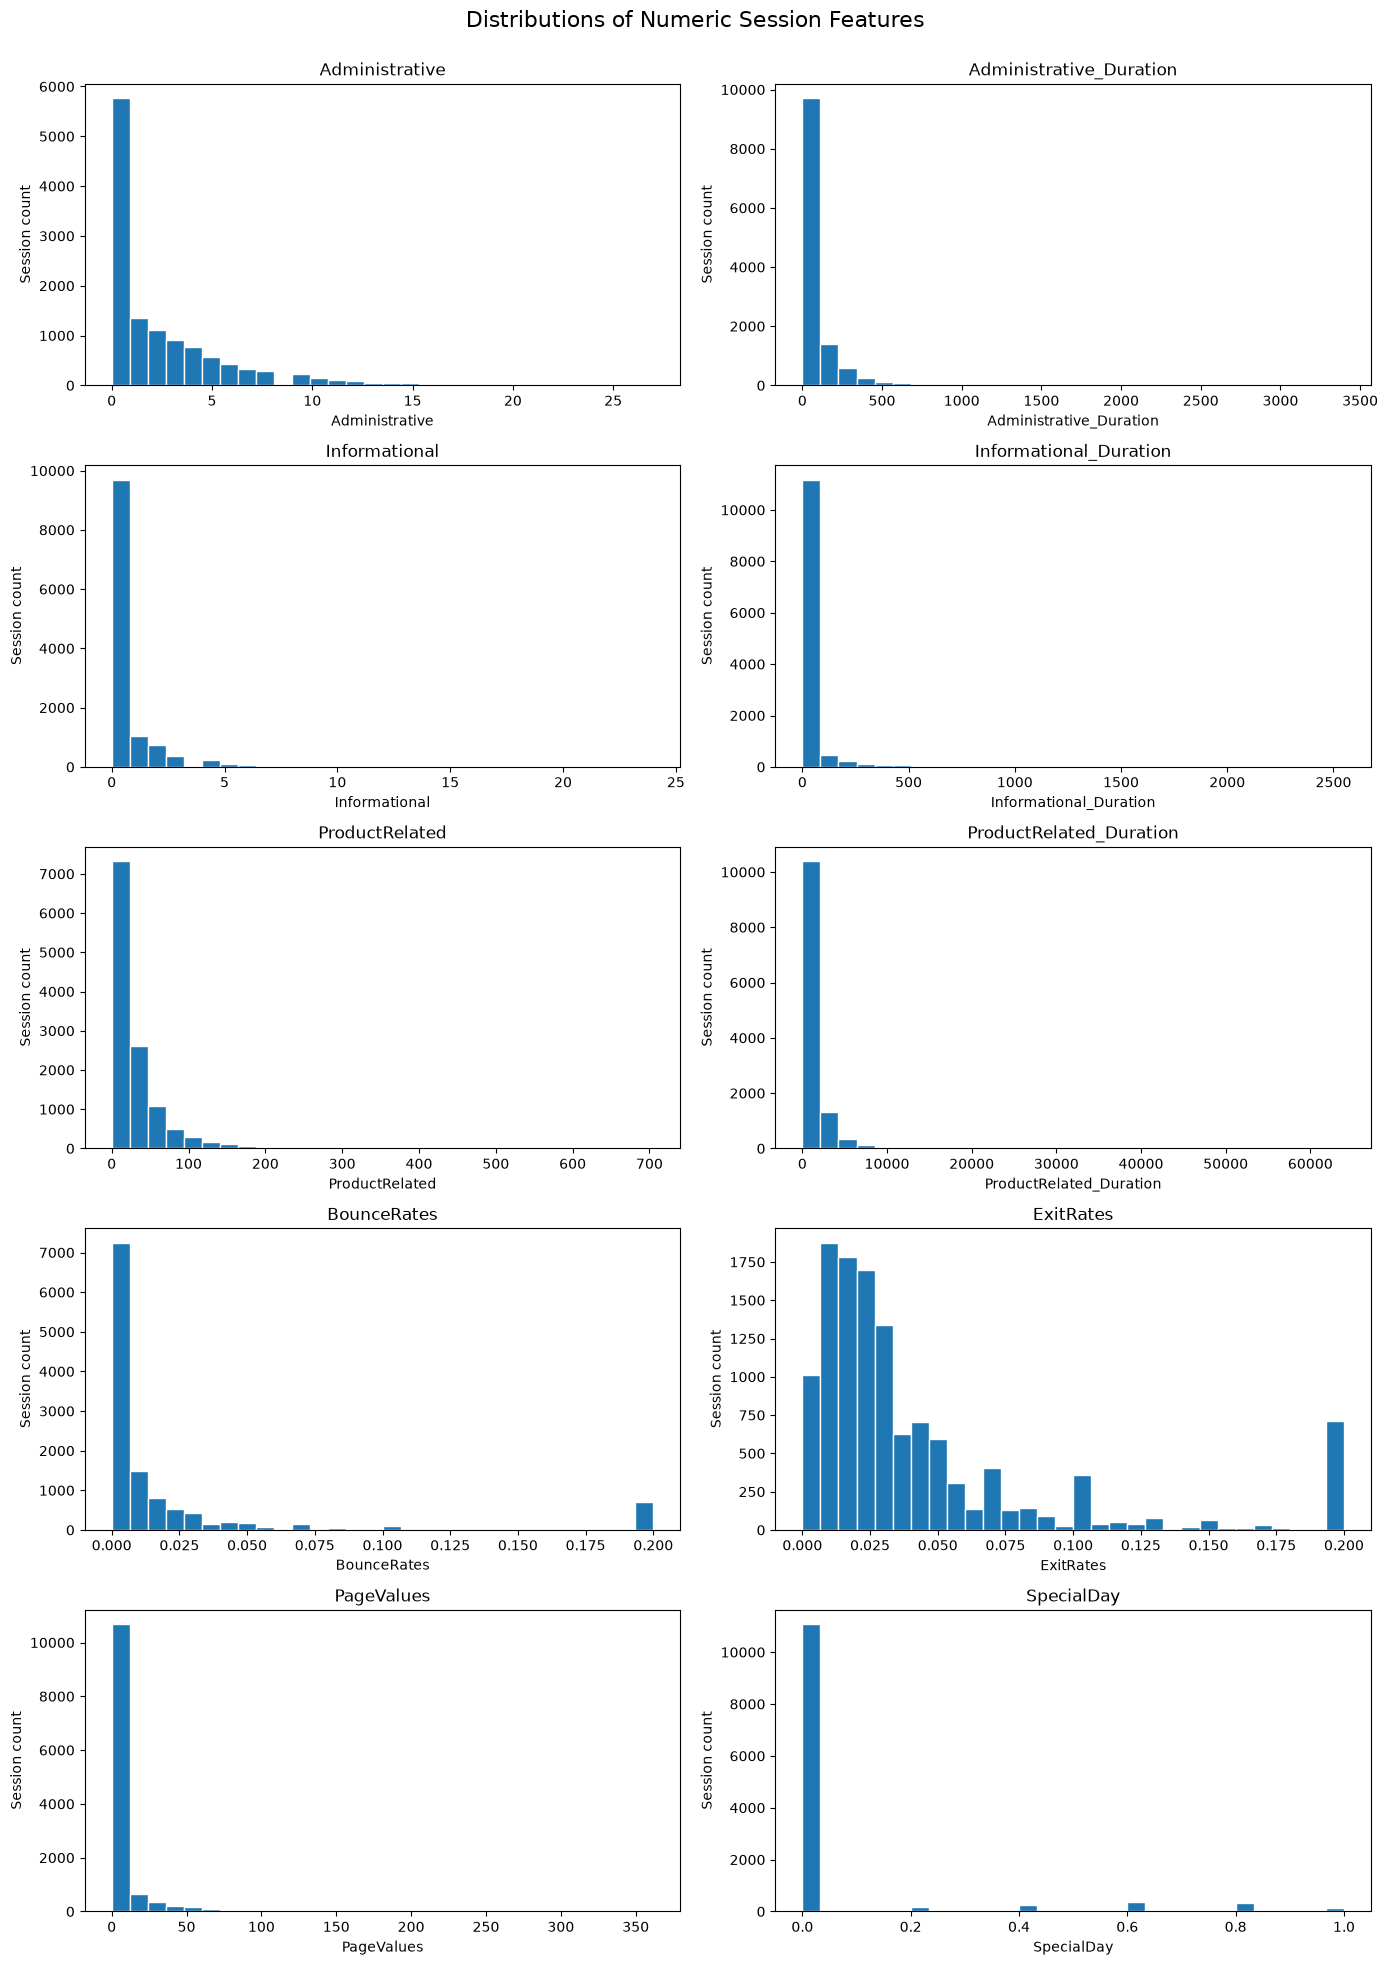

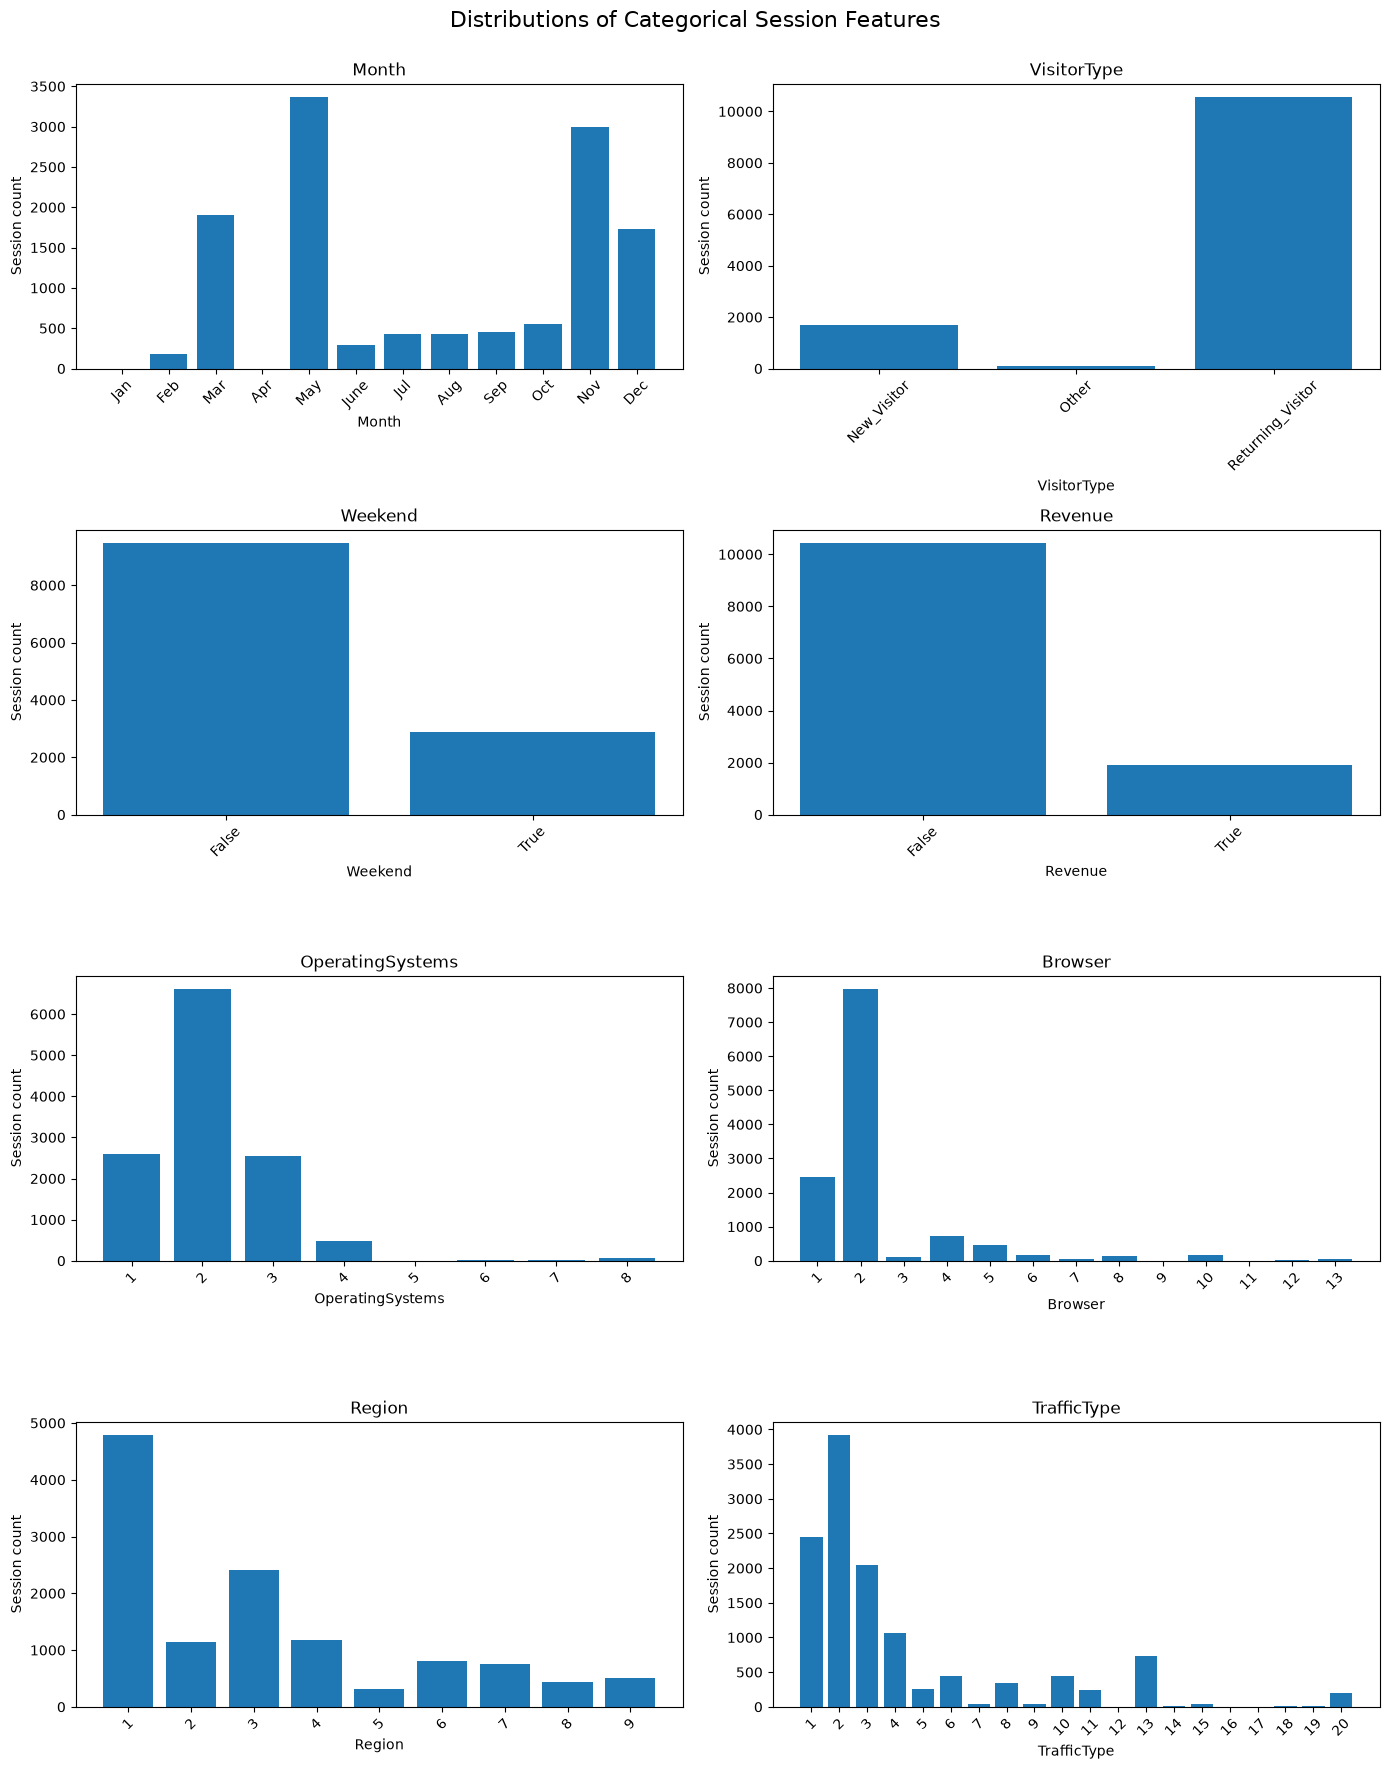

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
for column, ax in zip(measurement_columns, axes.flat):
    ax.hist(df_prepared[column], bins=30, edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Session count")
fig.suptitle("Distributions of Numeric Session Features", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

distribution_columns = ["Month", "VisitorType", "Weekend", "Revenue", "OperatingSystems", "Browser", "Region", "TrafficType"]
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for column, ax in zip(distribution_columns, axes.flat):
    counts = df_prepared[column].value_counts(sort=False, dropna=False)
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Session count")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Distributions of Categorical Session Features", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()